# Embeddings and metadata: basic analysis

Load the saved crystal embeddings and metadata, inspect their shapes and sizes,
and check that they are ready for graph construction. The embedding export script
saves metadata row `i` for embedding row `i`.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

# Works when the kernel starts at the repository root or in this notebook's folder.
candidates = [
    parent / relative
    for parent in (Path.cwd(), *Path.cwd().parents)
    for relative in ("data/data", "data")
]
data_dir = next(
    (folder for folder in candidates
     if (folder / "embeddings.npy").is_file()
     and (folder / "metadata.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Could not find embeddings.npy and metadata.csv under data/.")

embeddings_path = data_dir / "embeddings.npy"
metadata_path = data_dir / "metadata.csv"
embeddings = np.load(embeddings_path, allow_pickle=False)
metadata = pd.read_csv(metadata_path)

if embeddings.ndim != 2:
    raise ValueError(f"Expected a 2D embedding matrix; got {embeddings.shape}.")
if embeddings.shape[0] != len(metadata):
    raise ValueError("Embedding and metadata row counts do not match.")

print(f"Loaded data from: {data_dir.resolve()}")

Loaded data from: C:\Users\Atharv\OneDrive\Desktop\Books\NUS Courses\CS5284_Graph_Machine_Learning\ProjectProposal\crystal-ml-proposal\data\data


## Shape and size

Each embedding row represents one crystal; columns are embedding features.
File sizes measure storage on disk; memory sizes measure the loaded data
(including metadata strings and the DataFrame index). One MiB is 1,048,576 bytes.

In [3]:
overview = pd.DataFrame([
    {
        "dataset": "embeddings",
        "shape": embeddings.shape,
        "rows": embeddings.shape[0],
        "columns": embeddings.shape[1],
        "values": embeddings.size,
        "dtype": str(embeddings.dtype),
        "file_MiB": embeddings_path.stat().st_size / 1024**2,
        "memory_MiB": embeddings.nbytes / 1024**2,
    },
    {
        "dataset": "metadata",
        "shape": metadata.shape,
        "rows": metadata.shape[0],
        "columns": metadata.shape[1],
        "values": metadata.size,
        "dtype": "mixed",
        "file_MiB": metadata_path.stat().st_size / 1024**2,
        "memory_MiB": metadata.memory_usage(index=True, deep=True).sum() / 1024**2,
    },
]).set_index("dataset")
display(overview.round(3))

print("First 5 embeddings, first 8 features:")
display(pd.DataFrame(embeddings[:5, :8]).rename_axis(index="row", columns="feature"))

,shape,rows,columns,values,dtype,file_MiB,memory_MiB
dataset,,,,,,,
embeddings,"(27136, 512)",27136,512,13893632,float32,53.000,53.00
metadata,"(27136, 9)",27136,9,244224,mixed,2.442,7.99


First 5 embeddings, first 8 features:


feature,0,1,2,3,4,5,6,7
row,,,,,,,,
0,0.176838,-0.233124,0.943807,0.278604,0.292550,0.244189,-0.394159,-0.095398
1,0.664274,0.419569,-0.420122,0.021675,-0.641636,-0.008269,-0.067970,-0.122045
2,0.247701,0.160716,-0.100733,0.354944,-0.491770,0.295882,0.007223,-0.120738
3,0.580897,-0.102405,-0.645324,-0.212167,-0.944322,-1.080245,0.506458,-0.449573
4,0.059287,-0.328596,-0.089358,-0.949137,-0.378780,-0.059136,-0.014962,1.071118


## Metadata preview and statistics

Inspect the first five crystals, column types, missing values, unique-value
counts, and descriptive statistics for numeric columns.

In [4]:
display(metadata.head())

metadata_schema = pd.DataFrame({
    "dtype": metadata.dtypes.astype(str),
    "non_null": metadata.notna().sum(),
    "missing": metadata.isna().sum(),
    "unique": metadata.nunique(),
})
display(metadata_schema)
display(metadata.describe().T)

,material_id,formation_energy_per_atom,band_gap,pretty_formula,e_above_hull,elements,spacegroup.number,num_id,chemical_system
0,mp-1221227,-1.637460,0.2133,Na3MnCoNiO6,0.043001,"['Co', 'Mn', 'Na', 'Ni', 'O']",8,0,Co-Mn-Na-Ni-O
1,mp-974729,-0.314759,0.0000,Nd(Al2Cu)4,0.000000,"['Al', 'Cu', 'Nd']",139,1,Al-Cu-Nd
2,mp-1185360,-0.193761,0.0000,LiMnIr2,0.018075,"['Ir', 'Li', 'Mn']",225,2,Ir-Li-Mn
3,mp-1188861,-0.584694,3.8556,LiCSN,0.048847,"['C', 'Li', 'N', 'S']",62,3,C-Li-N-S
4,mp-677272,-2.474759,0.4707,La2EuS4,0.000000,"['Eu', 'La', 'S']",122,4,Eu-La-S


,dtype,non_null,missing,unique
material_id,object,27136,0,27136
formation_energy_per_atom,float64,27136,0,27094
band_gap,float64,27136,0,9816
pretty_formula,object,27136,0,23540
e_above_hull,float64,27136,0,15179
elements,object,27136,0,18016
spacegroup.number,int64,27136,0,169
num_id,int64,27136,0,27136
chemical_system,object,27136,0,16549


,count,mean,std,min,25%,50%,75%,max
formation_energy_per_atom,27136.0,-1.219803,1.029393,-5.153569,-2.01325,-0.814771,-0.400797,0.079825
band_gap,27136.0,0.791848,1.417775,0.000000,0.00000,0.000000,1.142100,17.902300
e_above_hull,27136.0,0.017478,0.023265,0.000000,0.00000,0.004073,0.031026,0.079999
spacegroup.number,27136.0,122.659972,79.843672,1.000000,51.00000,139.000000,194.000000,229.000000
num_id,27136.0,13567.500000,7833.632789,0.000000,6783.75000,13567.500000,20351.250000,27135.000000


## Embedding statistics and data checks

Summarize values across the embedding matrix and the L2 length of each row.
Row counts check consistency with the export format; they do not independently
prove that the rows are in the correct order. Non-finite values or zero-length
embeddings would need attention before distance-based graph construction.

In [5]:
finite_mask = np.isfinite(embeddings)
finite_values = embeddings[finite_mask]
embedding_stats = pd.Series({
    "min": finite_values.min() if finite_values.size else np.nan,
    "max": finite_values.max() if finite_values.size else np.nan,
    "mean": finite_values.mean(dtype=np.float64) if finite_values.size else np.nan,
    "std": finite_values.std(dtype=np.float64) if finite_values.size else np.nan,
}, name="finite_embedding_values")
display(embedding_stats.to_frame())

embedding_norms = np.linalg.norm(embeddings, axis=1)
display(pd.Series(embedding_norms, name="embedding_L2_norm").describe().to_frame())

checks = pd.Series({
    "row_counts_match": embeddings.shape[0] == len(metadata),
    "non_finite_embedding_values": int((~finite_mask).sum()),
    "zero_length_embeddings": int((embedding_norms == 0).sum()),
    "missing_metadata_values": int(metadata.isna().sum().sum()),
    "duplicate_material_ids": int(metadata["material_id"].duplicated().sum()),
}, name="result")
display(checks.to_frame())

,finite_embedding_values
min,-2.129747
max,1.993900
mean,0.000503
std,0.388382


,embedding_L2_norm
count,27136.000000
mean,8.787039
std,0.135800
min,8.322221
25%,8.706676
50%,8.813362
75%,8.893038
max,9.113167


,result
row_counts_match,True
non_finite_embedding_values,0
zero_length_embeddings,0
missing_metadata_values,0
duplicate_material_ids,0


## Chemical reference sets

Following [the upstream screening implementation](../../external/Crys_JEPA/V_screen.py),
the reference set for crystal `i` contains every available crystal whose element set
is a **non-empty subset** of crystal `i`'s element set. This includes the same chemical
system and all its subsystems, regardless of stoichiometry, formation energy, or distance.
For an `A-B-C` crystal, eligible systems are `A`, `B`, `C`, `A-B`, `A-C`, `B-C`, and `A-B-C`.

Here the reference pool is the loaded `metadata`, aligned row-for-row with `embeddings`.
The query itself is excluded by default because our queries are already in that pool;
`exclude_self=False` includes it. An empty result means no *other* reference is available.
Reference membership is directional: an `A-B` crystal is eligible for an `A-B-C` query,
while the `A-B-C` crystal is not eligible for the `A-B` query.

**Usage:** `get_reference_set("mp-1221227")`, `get_reference_set(0)`, or
`get_reference_set(index=0)`. An integer is a **zero-based row position**, corresponding
to `embeddings[index]`. The returned DataFrame is indexed by those embedding row positions.
Rerun the lookup-definition cell if you replace or reorder `metadata`.

In [9]:
from functools import lru_cache
from itertools import combinations
from numbers import Integral

# Index the available reference pool once; no structures, GPU, or energy labels are needed.
required_columns = {"material_id", "chemical_system"}
if not required_columns.issubset(metadata.columns):
    raise ValueError(f"metadata must contain {sorted(required_columns)}.")
if metadata[list(required_columns)].isna().any().any():
    raise ValueError("Material IDs and chemical systems must not be missing.")
if metadata["material_id"].duplicated().any():
    raise ValueError("Material IDs must be unique for unambiguous lookup.")

_reference_systems = metadata["chemical_system"].map(
    lambda system: "-".join(sorted(set(system.split("-"))))
)
_reference_groups = _reference_systems.groupby(_reference_systems, sort=False).indices
_material_id_to_position = {
    material_id: position
    for position, material_id in enumerate(metadata["material_id"])
}


@lru_cache(maxsize=None)
def _reference_positions(chemical_system):
    """Cached pool positions for all non-empty subsystems, including the full system."""
    elements = chemical_system.split("-")
    chunks = []
    for size in range(1, len(elements) + 1):
        for subsystem in combinations(elements, size):
            key = "-".join(sorted(subsystem))
            if key in _reference_groups:
                chunks.append(_reference_groups[key])
    if not chunks:
        return np.empty(0, dtype=np.intp)
    return np.sort(np.concatenate(chunks))


def get_reference_set(material_id=None, *, index=None, exclude_self=True):
    """Return chemically eligible metadata rows for a material ID or row position.

    Supply exactly one material ID (string) or zero-based positional index (integer).
    A positional integer argument is also accepted: get_reference_set(0).
    References have an element set contained in the query's element set.
    The query is excluded by default; no energy or distance filtering is applied.
    Returned index 'embedding_index' identifies rows in the embeddings array.

    Raises KeyError for unknown IDs, IndexError for out-of-range positions,
    and TypeError/ValueError for invalid or ambiguous arguments.
    """
    if (material_id is None) == (index is None):
        raise ValueError("Supply exactly one material_id or index.")
    if not isinstance(exclude_self, (bool, np.bool_)):
        raise TypeError("exclude_self must be a boolean.")

    if material_id is not None:
        if isinstance(material_id, str):
            if material_id not in _material_id_to_position:
                raise KeyError(f"Unknown material_id: {material_id!r}")
            position = _material_id_to_position[material_id]
        elif isinstance(material_id, Integral) and not isinstance(material_id, (bool, np.bool_)):
            position = int(material_id)
        else:
            raise TypeError("material_id must be a string ID or an integer row position.")
    else:
        if not isinstance(index, Integral) or isinstance(index, (bool, np.bool_)):
            raise TypeError("index must be an integer row position.")
        position = int(index)

    if not 0 <= position < len(metadata):
        raise IndexError(f"Row position must be between 0 and {len(metadata) - 1}.")

    positions = _reference_positions(_reference_systems.iloc[position])
    if exclude_self:
        positions = positions[positions != position]
    result = metadata.iloc[positions].copy()
    result.index = pd.Index(positions, name="embedding_index")
    return result

In [11]:
anchor_index = 1  # Change this to inspect another crystal.
anchor = metadata.iloc[anchor_index]
reference_set = get_reference_set(anchor["material_id"])
# Equivalent: get_reference_set(anchor_index) or get_reference_set(index=anchor_index).
# Include the anchor: get_reference_set(anchor_index, exclude_self=False).

print(f"Anchor row: {anchor_index}; ID: {anchor['material_id']}; system: {anchor['chemical_system']}")
print(f"Reference count (self excluded): {len(reference_set):,}")
print("First 10 reference crystals; embedding_index gives the corresponding embedding rows:")
display(reference_set.head(10))

Anchor row: 1; ID: mp-974729; system: Al-Cu-Nd
Reference count (self excluded): 22
First 10 reference crystals; embedding_index gives the corresponding embedding rows:


,material_id,formation_energy_per_atom,band_gap,pretty_formula,e_above_hull,elements,spacegroup.number,num_id,chemical_system
embedding_index,,,,,,,,,
260,mp-12802,-0.189439,0.0,AlCu3,0.000000,"['Al', 'Cu']",59,260,Al-Cu
270,mp-159,0.009010,0.0,Nd,0.009010,['Nd'],225,270,Nd
3133,mp-1220197,-0.222215,0.0,NdAlCu4,0.018005,"['Al', 'Cu', 'Nd']",187,3133,Al-Cu-Nd
4421,mp-1834,-0.303266,0.0,NdAl4,0.050253,"['Nd', 'Al']",139,4421,Al-Nd
5989,mp-16513,-0.441899,0.0,NdAl3,0.000000,"['Nd', 'Al']",194,5989,Al-Nd
7604,mp-12793,-0.350258,0.0,NdAl,0.042348,"['Al', 'Nd']",221,7604,Al-Nd
8287,mp-12777,-0.164554,0.0,AlCu3,0.024885,"['Al', 'Cu']",225,8287,Al-Cu
10585,mp-998,-0.165535,0.0,Al2Cu,0.012532,"['Al', 'Cu']",140,10585,Al-Cu
12478,mp-1022721,-0.139367,0.0,AlCu,0.074061,"['Al', 'Cu']",221,12478,Al-Cu


### Reference counts across the dataset

Count the available *other reference crystals* for each anchor, rather than the number
of chemical subsystems. Every anchor contributes one observation. Empty reference sets
are retained with count zero. These counts are independent of the graph's `k` value.

Quartiles are P25 (Q1), P50 (median/Q2), and P75 (Q3). Percentile thresholds use linear
interpolation and can be fractional. Quartile-defined groups keep equal counts together,
so their sizes can differ from exactly 25% of the dataset.

In [11]:
# Crystals sharing a chemical system share the same reference pool; subtract the anchor.
_reference_count_by_system = {
    system: len(_reference_positions(system)) - 1
    for system in _reference_groups
}
reference_counts = metadata[["material_id", "pretty_formula", "chemical_system"]].copy()
reference_counts.index = pd.RangeIndex(len(metadata), name="embedding_index")
reference_counts["n_references"] = _reference_systems.map(_reference_count_by_system).to_numpy()
ref_counts = reference_counts["n_references"]

reference_summary = ref_counts.agg(["count", "mean", "std", "min", "median", "max"]).to_frame("value")
reference_summary.loc["IQR", "value"] = ref_counts.quantile(0.75) - ref_counts.quantile(0.25)
print("Reference-count summary (self excluded):")
display(reference_summary.round(3))

percentile_levels = [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]
reference_percentiles = pd.DataFrame({
    "percentile": [f"P{p}" for p in percentile_levels],
    "reference_count": ref_counts.quantile(np.array(percentile_levels) / 100).to_numpy(),
    "quartile": [{25: "Q1", 50: "Q2 / median", 75: "Q3"}.get(p, "") for p in percentile_levels],
}).set_index("percentile")
print("Percentiles and quartiles:")
display(reference_percentiles)

q1, q2, q3 = ref_counts.quantile([0.25, 0.5, 0.75]).to_numpy()
reference_counts["quartile_group"] = pd.Categorical(
    np.select([ref_counts <= q1, ref_counts <= q2, ref_counts <= q3],
              ["Q1", "Q2", "Q3"], default="Q4"),
    categories=["Q1", "Q2", "Q3", "Q4"], ordered=True,
)
reference_quartile_groups = (
    reference_counts.groupby("quartile_group", observed=False)["n_references"]
    .agg(n_crystals="size", min_references="min", max_references="max")
)
reference_quartile_groups["percent_of_dataset"] = (
    100 * reference_quartile_groups["n_crystals"] / len(reference_counts)
)
print("Quartile-defined groups (ties kept together):")
display(reference_quartile_groups.round(2))

reference_availability = pd.DataFrame({
    "n_crystals": {
        "No other reference": int((ref_counts == 0).sum()),
        "Fewer than 10 references": int((ref_counts < 10).sum()),
        "Fewer than 50 references": int((ref_counts < 50).sum()),
    }
})
reference_availability["percent_of_dataset"] = 100 * reference_availability["n_crystals"] / len(ref_counts)
print("Availability checks (threshold rows overlap):")
display(reference_availability.round(2))

Reference-count summary (self excluded):


,value
count,27136.000
mean,24.246
std,26.295
min,0.000
median,18.000
max,283.000
IQR,16.000


Percentiles and quartiles:


,reference_count,quartile
percentile,,
P0,0.0,
P1,2.0,
P5,5.0,
P10,6.0,
P25,11.0,Q1
P50,18.0,Q2 / median
P75,27.0,Q3
P90,45.0,
P95,65.0,


Quartile-defined groups (ties kept together):


,n_crystals,min_references,max_references,percent_of_dataset
quartile_group,,,,
Q1,7446,0,11,27.44
Q2,7094,12,18,26.14
Q3,5814,19,27,21.43
Q4,6782,28,283,24.99


Availability checks (threshold rows overlap):


,n_crystals,percent_of_dataset
Fewer than 10 references,5473,20.17
Fewer than 50 references,24794,91.37
No other reference,33,0.12


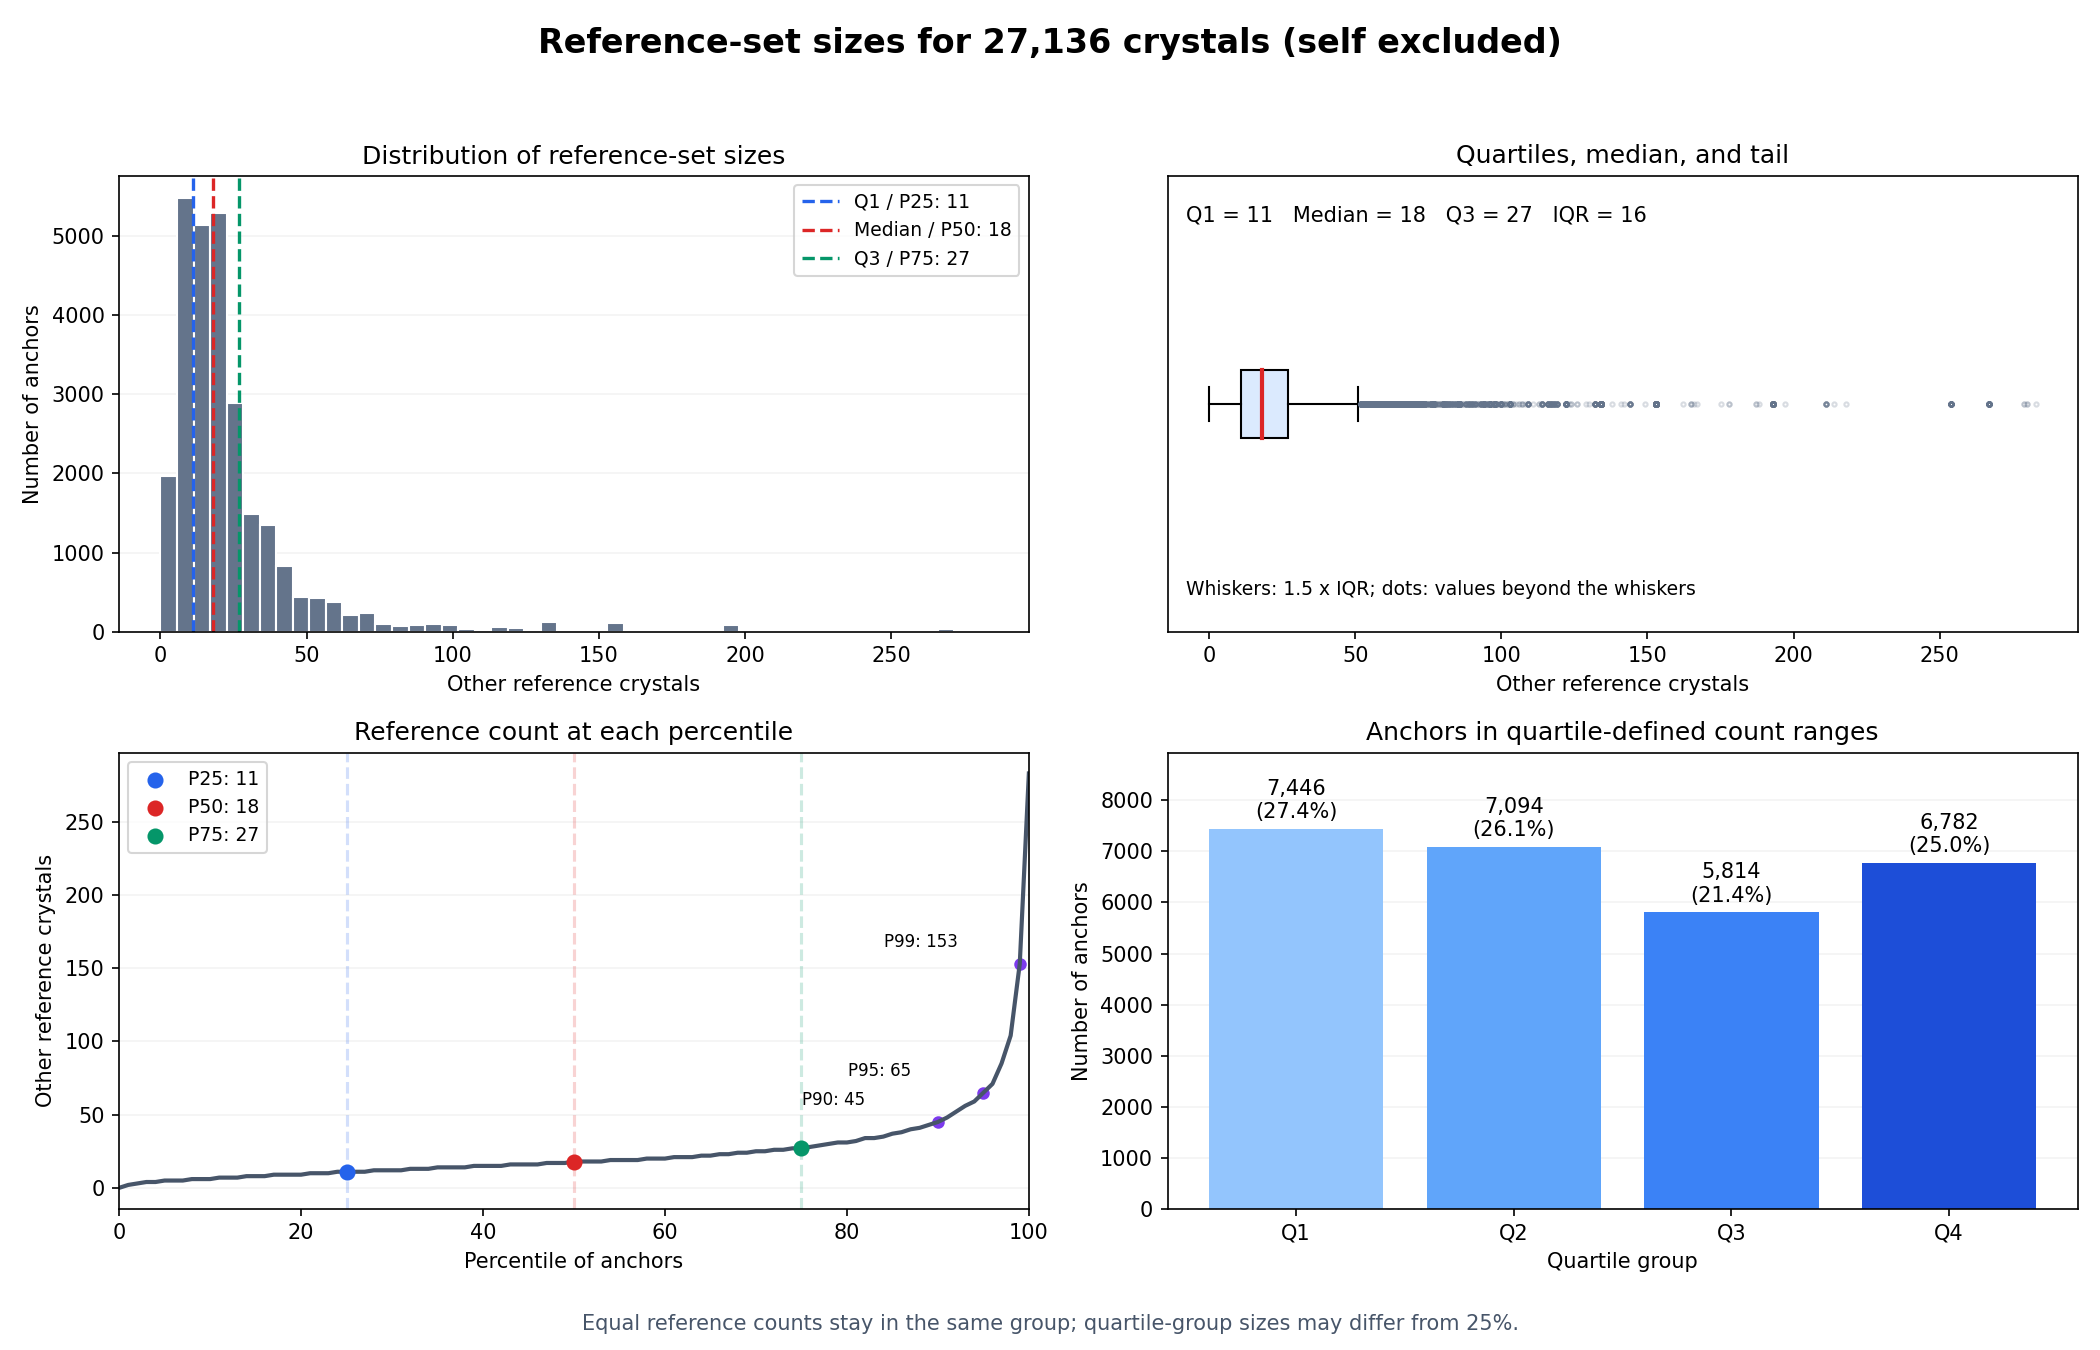

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
quartile_colors = ["#2563eb", "#dc2626", "#059669"]

ax = axes[0, 0]
ax.hist(ref_counts, bins=50, color="#64748b", edgecolor="white")
for threshold, label, color in zip([q1, q2, q3], ["Q1 / P25", "Median / P50", "Q3 / P75"], quartile_colors):
    ax.axvline(threshold, color=color, linestyle="--", linewidth=1.6,
               label=f"{label}: {threshold:g}")
ax.set(title="Distribution of reference-set sizes", xlabel="Other reference crystals", ylabel="Number of anchors")
ax.legend(fontsize=9)

ax = axes[0, 1]
ax.boxplot(ref_counts.to_numpy(), vert=False, patch_artist=True,
           boxprops={"facecolor": "#dbeafe"}, medianprops={"color": "#dc2626", "linewidth": 2},
           flierprops={"marker": ".", "markersize": 4, "alpha": 0.25, "markeredgecolor": "#64748b"})
ax.set(title="Quartiles, median, and tail", xlabel="Other reference crystals", yticks=[])
ax.text(0.02, 0.9, f"Q1 = {q1:g}   Median = {q2:g}   Q3 = {q3:g}   IQR = {q3 - q1:g}",
        transform=ax.transAxes, fontsize=10)
ax.text(0.02, 0.08, "Whiskers: 1.5 x IQR; dots: values beyond the whiskers", transform=ax.transAxes, fontsize=9)

ax = axes[1, 0]
percentile_grid = np.arange(101)
ax.plot(percentile_grid, ref_counts.quantile(percentile_grid / 100).to_numpy(), color="#475569", linewidth=2)
for percentile, threshold, color in zip([25, 50, 75], [q1, q2, q3], quartile_colors):
    ax.scatter(percentile, threshold, color=color, s=45, zorder=3,
               label=f"P{percentile}: {threshold:g}")
    ax.axvline(percentile, color=color, alpha=0.2, linestyle="--")
for percentile in [90, 95, 99]:
    threshold = ref_counts.quantile(percentile / 100)
    ax.scatter(percentile, threshold, color="#7c3aed", s=25)
    ax.annotate(f"P{percentile}: {threshold:g}", (percentile, threshold),
                xytext=(-65, 8), textcoords="offset points", fontsize=8)
ax.set(title="Reference count at each percentile", xlabel="Percentile of anchors", ylabel="Other reference crystals", xlim=(0, 100))
ax.legend(loc="upper left", fontsize=9)

ax = axes[1, 1]
labels = reference_quartile_groups.index.astype(str)
bars = ax.bar(labels, reference_quartile_groups["n_crystals"],
              color=["#93c5fd", "#60a5fa", "#3b82f6", "#1d4ed8"])
for bar, count, percentage in zip(bars, reference_quartile_groups["n_crystals"],
                                  reference_quartile_groups["percent_of_dataset"]):
    ax.annotate(f"{count:,}\n({percentage:.1f}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10)
ax.set(title="Anchors in quartile-defined count ranges", xlabel="Quartile group", ylabel="Number of anchors")
ax.set_ylim(0, reference_quartile_groups["n_crystals"].max() * 1.2)

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle(f"Reference-set sizes for {len(ref_counts):,} crystals (self excluded)", fontsize=16, fontweight="bold")
fig.text(0.5, 0.015, "Equal reference counts stay in the same group; quartile-group sizes may differ from 25%.",
         ha="center", fontsize=10, color="#475569")
fig.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

## Construct a Gaussian-weighted Euclidean k-NN graph

`build_knn_graph(embeddings, k)` returns a SciPy CSR adjacency matrix `W`.
It centers each feature, computes all pairwise Euclidean distances in chunks,
sorts each row, and selects the first `k` neighbors after excluding the point itself.
Centering preserves Euclidean distances; no feature scaling or row normalization is applied.

For selected directed edges, the Gaussian weight is
$W_{ij} = \exp(-d_{ij}^2 / (2\sigma^2))$; all other entries are zero.
By default, `sigma` is the median of the strictly positive selected neighbor distances
(or 1 if all are zero). Pass `sigma=` to choose a fixed bandwidth.
Finally, $W_{ij} \leftarrow \max(W_{ij}, W_{ji})$ makes the graph undirected,
using the sparse comparison and multiplication technique below. A one-way edge
keeps its full weight in both directions; mutual edges use the larger weight.
The symmetric graph can have more than `k` neighbors per node and has no self-loops.

The full distance matrix for 27,136 points would use about 5.49 GiB in float64,
before sorting. [Scikit-learn's chunked pairwise distances](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise_distances_chunked.html)
compute the same distances in blocks. `working_memory` controls the target distance-block
size in MiB, not total process memory; sorting needs additional space. Computation is
still quadratic in the number of points, and each distance row is fully sorted.
Dependencies: `numpy`, `pandas`, `scipy`, and `scikit-learn`.

In [6]:
from numbers import Integral, Real

from scipy.sparse import csr_matrix
from sklearn.metrics import pairwise_distances_chunked


def build_knn_graph(embeddings, k, *, sigma=None, working_memory=64):
    """Return a symmetric, Gaussian-weighted Euclidean k-NN graph as CSR.

    Parameters
    ----------
    embeddings : array-like of shape (n_samples, n_features)
        Finite real-valued embeddings. Input values and row order are preserved.
    k : int
        Neighbors selected per point before symmetrization, 1 <= k < n_samples.
    sigma : float or None
        Positive Gaussian bandwidth. None uses the median positive k-NN distance,
        falling back to 1.0 when every selected distance is zero.
    working_memory : float
        Positive target distance-chunk size in MiB (excludes sorting overhead).

    Returns
    -------
    W : scipy.sparse.csr_matrix of shape (n_samples, n_samples)
        Elementwise max(A, A.T), where A contains directed Gaussian k-NN weights.
        The diagonal is zero; row i corresponds to input embedding row i.
        Equal-distance ties are resolved by input row index.
    """
    X = np.asarray(embeddings)
    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] == 0:
        raise ValueError("embeddings must be 2D with at least 2 rows and 1 feature.")
    if X.dtype.kind not in "iuf" or not np.isfinite(X).all():
        raise ValueError("embeddings must contain only finite real numeric values.")
    n_samples = X.shape[0]
    if isinstance(k, (bool, np.bool_)) or not isinstance(k, Integral) or not 1 <= k < n_samples:
        raise ValueError("k must be an integer with 1 <= k < n_samples.")
    if sigma is not None and (
        not isinstance(sigma, Real) or not np.isfinite(sigma) or sigma <= 0
    ):
        raise ValueError("sigma must be a finite positive number or None.")
    if not isinstance(working_memory, Real) or not np.isfinite(working_memory) or working_memory <= 0:
        raise ValueError("working_memory must be a finite positive number of MiB.")

    # 1. Center each feature using a copy, leaving the original embeddings intact.
    X = X.astype(np.float64, copy=True)
    X -= X.mean(axis=0, keepdims=True)

    neighbor_indices = np.empty((n_samples, k), dtype=np.intp)
    neighbor_distances = np.empty((n_samples, k), dtype=np.float64)

    # 2-4. Compute pairwise distances, sort each row, and retain k non-self neighbors.
    start = 0
    for D in pairwise_distances_chunked(
        X, metric="euclidean", working_memory=working_memory
    ):
        stop = start + D.shape[0]
        local_rows = np.arange(D.shape[0])
        D[local_rows, np.arange(start, stop)] = np.inf
        # Stable sorting breaks ties by column index, including duplicate points.
        nearest = np.argsort(D, axis=1, kind="stable")[:, :k]
        neighbor_indices[start:stop] = nearest
        neighbor_distances[start:stop] = np.take_along_axis(D, nearest, axis=1)
        start = stop

    # 5. Gaussian weights on the selected edges only.
    if sigma is None:
        positive_distances = neighbor_distances[neighbor_distances > 0]
        sigma = float(np.median(positive_distances)) if positive_distances.size else 1.0
    with np.errstate(over="ignore", under="ignore"):
        weights = np.exp(-0.5 * (neighbor_distances / sigma) ** 2)

    # 6. Construct sparse adjacency directly, without allocating a dense W.
    rows = np.repeat(np.arange(n_samples), k)
    W = csr_matrix(
        (weights.ravel(), (rows, neighbor_indices.ravel())),
        shape=(n_samples, n_samples),
    )

    # 7. Make W symmetric by keeping the larger weight in each direction.
    bigger = W.T > W
    W = W - W.multiply(bigger) + W.T.multiply(bigger)
    W = W.tocsr()
    W.eliminate_zeros()
    W.sort_indices()
    return W

In [7]:
from time import perf_counter

from scipy.sparse.csgraph import connected_components

k = 10  # Change k here and rerun to construct another graph.
started = perf_counter()
W = build_knn_graph(embeddings, k)
elapsed = perf_counter() - started

degree = np.diff(W.indptr)
n_components, component_labels = connected_components(W, directed=False)
graph_summary = pd.Series({
    "k_before_symmetrization": k,
    "adjacency_shape": W.shape,
    "format": W.format,
    "stored_nonzero_weights": W.nnz,
    "undirected_edges": W.nnz // 2,
    "density": W.nnz / (W.shape[0] * W.shape[1]),
    "sparse_memory_MiB": (W.data.nbytes + W.indices.nbytes + W.indptr.nbytes) / 1024**2,
    "min_degree": degree.min(),
    "mean_degree": degree.mean(),
    "max_degree": degree.max(),
    "connected_components": n_components,
    "self_loops": np.count_nonzero(W.diagonal()),
    "symmetric": (W != W.T).nnz == 0,
    "build_seconds": elapsed,
}, name="value")
display(graph_summary.to_frame())
print("First 5 x 5 adjacency entries (small dense preview only):")
display(pd.DataFrame(W[:5, :5].toarray()))

,value
k_before_symmetrization,10
adjacency_shape,"(27136, 27136)"
format,csr
stored_nonzero_weights,402272
undirected_edges,201136
density,0.000546
sparse_memory_MiB,4.707157
min_degree,10
mean_degree,14.824292
max_degree,35


First 5 x 5 adjacency entries (small dense preview only):


,0,1,2,3,4
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0


In [8]:
W.shape

(27136, 27136)